Vaishnavi Pundhir


2026B16310325

CSE AIML 6

BATCH 7 DATA ANALYST

In [3]:
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Running locally: using the CSV files in this folder.")

Saving stations.csv to stations.csv
Saving air_quality.csv to air_quality (1).csv
Saving weather.csv to weather (1).csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

air = pd.read_csv("air_quality.csv")
weather = pd.read_csv("weather.csv")
stations = pd.read_csv("stations.csv")

print("Air-quality rows:", len(air))
print("Weather rows:", len(weather))
display(air.head())
display(weather.head())

Air-quality rows: 4280
Weather rows: 3843


,station_id,timestamp,unit,pm25,pm10,no2,o3
0,ST01,2025-01-01 00:00:00,ug/m3,86.10,176.09,24.44,23.96
1,ST01,2025-01-01 06:00:00,ug/m3,69.24,115.11,27.56,19.70
2,st01,2025-01-01 12:00:00,ug/m3,73.69,152.88,NaN,47.05
3,ST01,2025-01-01 18:00:00,ug/m3,69.73,143.32,42.10,22.48
4,ST01,2025-01-02 00:00:00,ug/m3,73.85,134.13,23.87,17.58


,station_id,timestamp,temperature_c,humidity_pct,wind_kmh,rainfall_mm
0,ST01,2025-01-01 00:00:00,7.2,54.2,11.8,0.0
1,ST01,2025-01-01 06:00:00,11.7,63.9,4.7,0.0
2,st01,2025-01-01 12:00:00,16.7,49.7,3.9,0.0
3,ST01,2025-01-02 00:00:00,11.6,62.8,9.6,0.0
4,ST01,2025-01-02 06:00:00,14.6,54.7,3.9,0.0


In [5]:
pollutants = ["pm25", "pm10", "no2", "o3"]

for data in [air, weather, stations]:
    data["station_id"] = data["station_id"].str.strip().str.upper()

air["timestamp"] = pd.to_datetime(air["timestamp"], errors="coerce", utc=True)
weather["timestamp"] = pd.to_datetime(weather["timestamp"], errors="coerce", utc=True)

air["unit"] = air["unit"].str.strip().str.lower()
for col in pollutants:
    air[col] = pd.to_numeric(air[col], errors="coerce")
    air.loc[air["unit"] == "mg/m3", col] *= 1000
    air.loc[air[col] < 0, col] = np.nan

air.loc[~air["unit"].isin(["mg/m3", "ug/m3"]), pollutants] = np.nan
air["unit"] = "ug/m3"
air = air.dropna(subset=["timestamp", "station_id"])
weather = weather.dropna(subset=["timestamp", "station_id"])

# Keep one observation for each station and timestamp.
duplicate_rows = air.duplicated(subset=["station_id", "timestamp"]).sum()
print("Duplicate rows found:", duplicate_rows)
air = air.drop_duplicates(subset=["station_id", "timestamp"])
weather = weather.drop_duplicates(subset=["station_id", "timestamp"])
print("Rows after cleaning:", len(air))

Duplicate rows found: 8
Rows after cleaning: 4272


In [6]:
print("Missing values in air data:")
print(air[pollutants].isna().sum())

# Sample year 2025: 365 days × 4 expected readings per day.
expected_readings = 365 * 4
quality = air.groupby("station_id").agg(
    available_rows=("timestamp", "count"),
    pm25_missing=("pm25", lambda x: x.isna().sum()),
    pm10_missing=("pm10", lambda x: x.isna().sum()),
    no2_missing=("no2", lambda x: x.isna().sum()),
    o3_missing=("o3", lambda x: x.isna().sum())
).reset_index()

quality["expected_rows"] = expected_readings
quality["missing_timestamps"] = expected_readings - quality["available_rows"]
quality["timestamp_coverage_%"] = (100 * quality["available_rows"] / expected_readings).round(1)
quality = quality.merge(stations, on="station_id", how="left")
display(quality)

Missing values in air data:
pm25    108
pm10    128
no2     103
o3      105
dtype: int64


,station_id,available_rows,pm25_missing,pm10_missing,no2_missing,o3_missing,expected_rows,missing_timestamps,timestamp_coverage_%,station_name,area_type
0,ST01,1422,28,39,36,29,1460,38,97.4,City Centre,Mixed area
1,ST02,1417,43,38,30,33,1460,43,97.1,Traffic Road,Busy road
2,ST03,1433,37,51,37,43,1460,27,98.2,Park Area,Green area


In [7]:
pm25_values = air["pm25"].dropna().to_numpy()

p25, median, p75, p95 = np.percentile(pm25_values, [25, 50, 75, 95])
iqr = p75 - p25
spike_count = np.sum(pm25_values > p95)

print("PM2.5 median:", round(median, 1), "µg/m³")
print("PM2.5 95th percentile:", round(p95, 1), "µg/m³")
print("PM2.5 IQR:", round(iqr, 1), "µg/m³")
print("Readings above sample 95th percentile:", spike_count)
print("Readings above 50 µg/m³ (example cutoff, NOT a compliance test):", np.sum(pm25_values > 50))

PM2.5 median: 48.0 µg/m³
PM2.5 95th percentile: 87.8 µg/m³
PM2.5 IQR: 33.4 µg/m³
Readings above sample 95th percentile: 209
Readings above 50 µg/m³ (example cutoff, NOT a compliance test): 1937


In [8]:
station_summary = air.groupby("station_id")[pollutants].agg(["mean", "median", "max"]).round(1)
print("Pollutant summaries by station:")
display(station_summary)

air["date"] = air["timestamp"].dt.date

daily = air.groupby(["station_id", "date"]).agg(
    pm25_mean=("pm25", "mean"),
    valid_readings=("pm25", "count")
)

# Add dates where a station had no observations at all.
all_days = pd.date_range("2025-01-01", "2025-12-31", freq="D").date
all_pairs = pd.MultiIndex.from_product(
    [stations["station_id"], all_days], names=["station_id", "date"]
)
daily = daily.reindex(all_pairs)
daily["valid_readings"] = daily["valid_readings"].fillna(0).astype(int)
daily["daily_coverage_%"] = daily["valid_readings"] / 4 * 100
daily.loc[daily["valid_readings"] < 3, "pm25_mean"] = np.nan
daily = daily.reset_index()

daily["month"] = pd.to_datetime(daily["date"]).dt.strftime("%Y-%m")
monthly = daily.groupby(["station_id", "month"]).agg(
    pm25_mean=("pm25_mean", "mean"),
    days_with_good_coverage=("pm25_mean", "count"),
    days_expected=("date", "count")
).reset_index()
monthly["day_coverage_%"] = (
    100 * monthly["days_with_good_coverage"] / monthly["days_expected"]
).round(1)

display(daily.head())
display(monthly.head())

Pollutant summaries by station:


pm25                 pm10                 no2                 o3  \
            mean median    max   mean median    max  mean median   max  mean   
station_id                                                                     
ST01        51.0   50.5  154.5   99.4   98.9  202.8  27.7   27.5  56.1  31.6   
ST02        63.3   62.1  308.0  117.7  116.3  225.8  39.9   39.6  71.3  28.0   
ST03        31.3   30.7  166.7   64.9   64.7  159.7  13.6   13.4  38.6  35.8   

                         
           median   max  
station_id               
ST01         28.8  75.2  
ST02         25.1  71.3  
ST03         33.2  70.4

,station_id,date,pm25_mean,valid_readings,daily_coverage_%,month
0,ST01,2025-01-01,74.6900,4,100.0,2025-01
1,ST01,2025-01-02,62.4175,4,100.0,2025-01
2,ST01,2025-01-03,60.5150,4,100.0,2025-01
3,ST01,2025-01-04,66.4750,4,100.0,2025-01
4,ST01,2025-01-05,71.0375,4,100.0,2025-01


,station_id,month,pm25_mean,days_with_good_coverage,days_expected,day_coverage_%
0,ST01,2025-01,70.199839,31,31,100.0
1,ST01,2025-02,65.680617,27,28,96.4
2,ST01,2025-03,56.909361,30,31,96.8
3,ST01,2025-04,46.456322,29,30,96.7
4,ST01,2025-05,42.388750,30,31,96.8


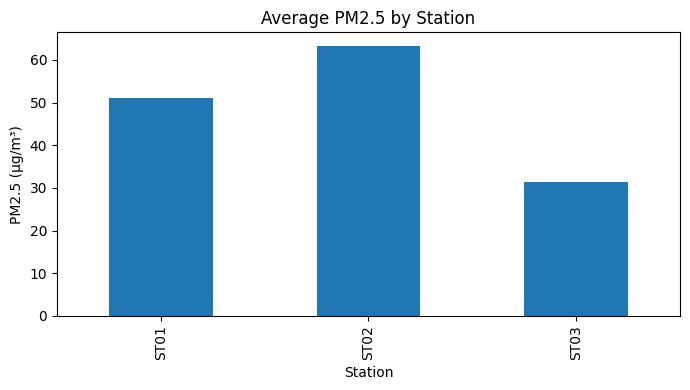

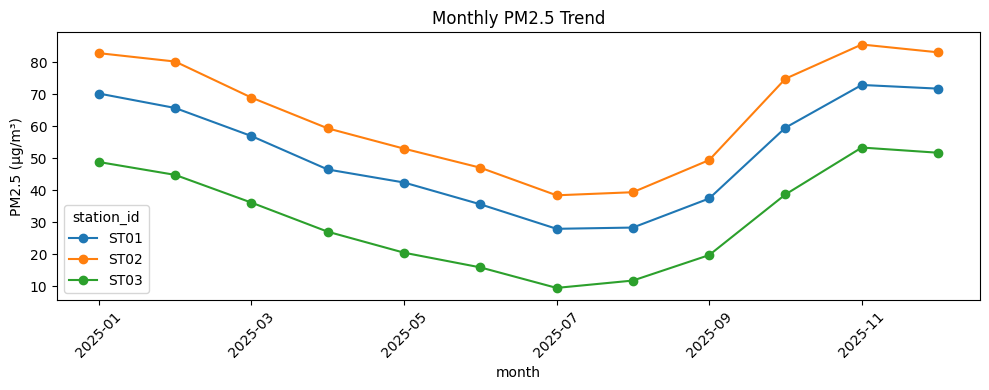

In [9]:
# Chart 1: average PM2.5 at each station
station_pm25 = air.groupby("station_id")["pm25"].mean()
station_pm25.plot(kind="bar", figsize=(7, 4), title="Average PM2.5 by Station")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Station")
plt.tight_layout()
plt.show()

# Chart 2: monthly PM2.5 (one line for each station)
monthly_chart = monthly.pivot(index="month", columns="station_id", values="pm25_mean")
monthly_chart.plot(figsize=(10, 4), marker="o", title="Monthly PM2.5 Trend")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

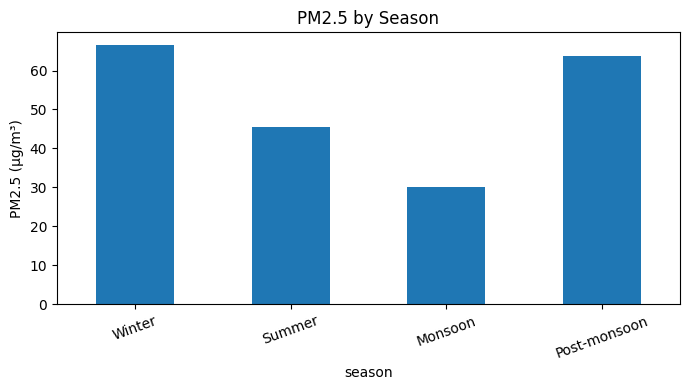

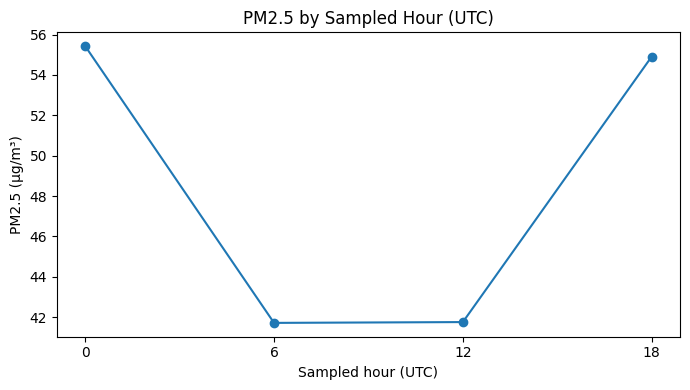

In [10]:
# Define seasons for this example (Northern India-style months).
air["month_number"] = air["timestamp"].dt.month

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-monsoon"

air["season"] = air["month_number"].apply(get_season)
air["hour"] = air["timestamp"].dt.hour

# Chart 3: seasons
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
season_mean = air.groupby("season")["pm25"].mean().reindex(season_order)
season_mean.plot(kind="bar", figsize=(7, 4), title="PM2.5 by Season")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Chart 4: hour of day (only the four sampled hours)
hour_mean = air.groupby("hour")["pm25"].mean()
hour_mean.plot(kind="line", marker="o", figsize=(7, 4), title="PM2.5 by Sampled Hour (UTC)")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Sampled hour (UTC)")
plt.xticks([0, 6, 12, 18])
plt.tight_layout()
plt.show()

Air rows without matching weather: 429
Correlation with PM2.5:
pm25             1.00
temperature_c   -0.61
humidity_pct    -0.37
wind_kmh        -0.33
rainfall_mm     -0.18
Name: pm25, dtype: float64


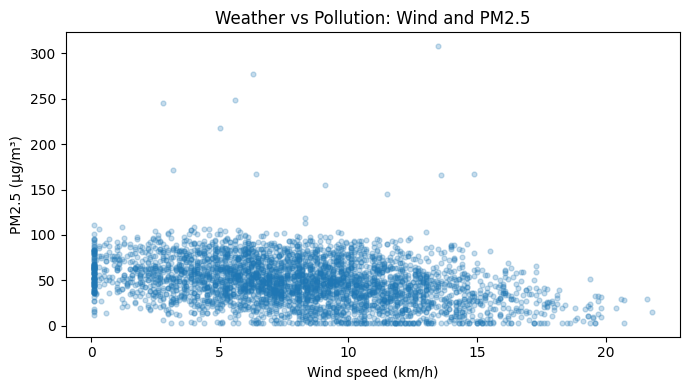

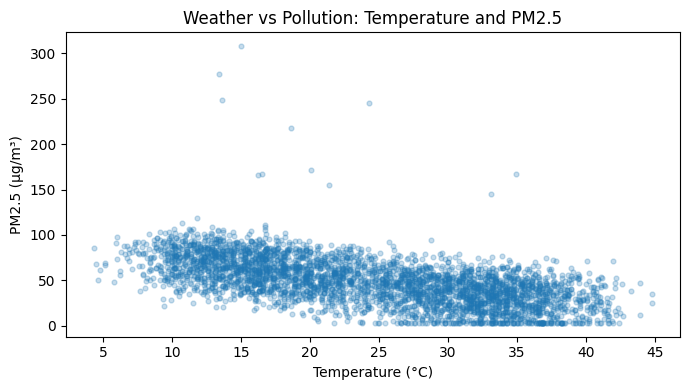

In [11]:
combined = air.merge(
    weather,
    on=["station_id", "timestamp"],
    how="left"
)

print("Air rows without matching weather:", combined["temperature_c"].isna().sum())
weather_columns = ["temperature_c", "humidity_pct", "wind_kmh", "rainfall_mm"]
correlations = combined[["pm25"] + weather_columns].corr()["pm25"].round(2)
print("Correlation with PM2.5:")
print(correlations)

# Chart 5: wind vs pollution
plt.figure(figsize=(7, 4))
plt.scatter(combined["wind_kmh"], combined["pm25"], alpha=0.25, s=12)
plt.xlabel("Wind speed (km/h)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Weather vs Pollution: Wind and PM2.5")
plt.tight_layout()
plt.show()

# Chart 6: temperature vs pollution
plt.figure(figsize=(7, 4))
plt.scatter(combined["temperature_c"], combined["pm25"], alpha=0.25, s=12)
plt.xlabel("Temperature (°C)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Weather vs Pollution: Temperature and PM2.5")
plt.tight_layout()
plt.show()

,months_above_50,months_with_data,spike_readings
station_id,,,
ST02,8,12,172
ST01,6,12,33
ST03,2,12,4


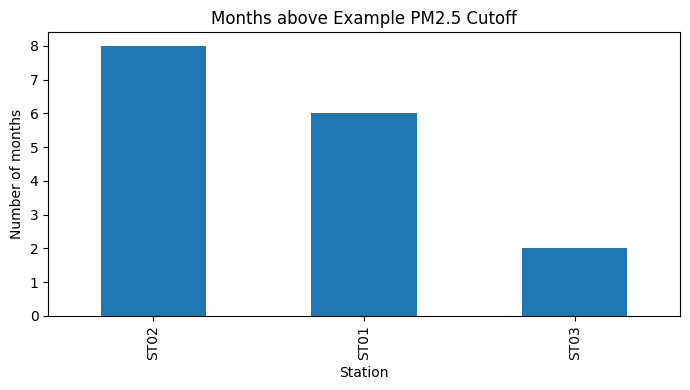

In [12]:
hotspots = monthly.groupby("station_id").agg(
    months_above_50=("pm25_mean", lambda x: (x > 50).sum()),
    months_with_data=("pm25_mean", "count")
)

spikes = air[air["pm25"] > p95].groupby("station_id").size()
hotspots["spike_readings"] = spikes
hotspots["spike_readings"] = hotspots["spike_readings"].fillna(0).astype(int)
hotspots = hotspots.sort_values("months_above_50", ascending=False)
display(hotspots)

# Chart 7: hotspot comparison
hotspots["months_above_50"].plot(kind="bar", figsize=(7, 4), title="Months above Example PM2.5 Cutoff")
plt.ylabel("Number of months")
plt.xlabel("Station")
plt.tight_layout()
plt.show()

In [13]:
top_station = station_pm25.idxmax()
print("PROJECT FINDINGS (ONLY FOR SYNTHETIC SAMPLE DATA)")
print("1. Highest average PM2.5 station:", top_station)
print("2. Season with highest average PM2.5:", season_mean.idxmax())
print("3. Highest number of monthly hotspot flags:", hotspots.index[0])
print("4. Wind vs PM2.5 correlation:", correlations["wind_kmh"])
print("5. Weather correlation is not proof of cause and effect.")

quality.to_csv("station_quality_report.csv", index=False)
station_summary.to_csv("pollutant_summary.csv")
daily.to_csv("daily_pm25.csv", index=False)
monthly.to_csv("monthly_pm25.csv", index=False)
hotspots.to_csv("hotspot_analysis.csv")
correlations.to_csv("weather_correlations.csv", header=["correlation_with_pm25"])
print("Saved 6 CSV result tables. In Colab, find them in the Files panel on the left.")

PROJECT FINDINGS (ONLY FOR SYNTHETIC SAMPLE DATA)
1. Highest average PM2.5 station: ST02
2. Season with highest average PM2.5: Winter
3. Highest number of monthly hotspot flags: ST02
4. Wind vs PM2.5 correlation: -0.33
5. Weather correlation is not proof of cause and effect.
Saved 6 CSV result tables. In Colab, find them in the Files panel on the left.
